# Задача 9

Методом прогонки решить разностный аналог граничной задачи для уравнения

$$
    y''=\cos x
$$

на промежутке $-\pi/2<x<\pi/2$. Рассмотреть различные варианты граничных
условий (на функцию и её производную).

---

## Аналитическое решение.

Дважды интегрируя, получаем общее решение

$$
    y(x)=-\cos x+C_1x+C_2, \qquad y'(x)=\sin x+C_1.
$$

На концах $\cos(\pm\pi/2)=0$, $\sin(\pm\pi/2)=\pm1$, поэтому

$$
    y\!\left(\pm\frac\pi2\right)=\pm\frac\pi2C_1+C_2, \qquad
    y'\!\left(\pm\frac\pi2\right)=\pm1+C_1.
$$

Рассмотрим четыре варианта граничных условий. Граничные значения
выберем ненулевыми, чтобы проверить, как они попадают в правую часть.

| Вариант | Слева, $x=-\pi/2$ | Справа, $x=\pi/2$ | Точное решение |
|:---:|:---:|:---:|:---:|
| I | $y=1$ | $y=2$ | $-\cos x+x/\pi+3/2$ |
| II | $y'=1$ | $y=0$ | $-\cos x+2x-\pi$ |
| III | $y=0$ | $y'=0$ | $-\cos x-x-\pi/2$ |
| IV | $y'=0$ | $y'=2$ | $-\cos x+x+C_2$, $C_2$ любое |

В варианте IV производная задана на обоих концах. Интегрируя уравнение,
получаем условие разрешимости

$$
    y'\!\left(\frac\pi2\right)-y'\!\left(-\frac\pi2\right)
    =\int_{-\pi/2}^{\pi/2}\cos x\,dx=2.
$$

Если оно нарушено, решения нет, а если выполнено, решение определено
лишь с точностью до константы. Этот случай разберём отдельно.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x_left = -np.pi / 2
x_right = np.pi / 2


def f(x):
    return np.cos(x)


variants = {
    "I":   dict(left=("y", 1.0), right=("y", 2.0),
                exact=lambda x: -np.cos(x) + x/np.pi + 1.5),
    "II":  dict(left=("dy", 1.0), right=("y", 0.0),
                exact=lambda x: -np.cos(x) + 2*x - np.pi),
    "III": dict(left=("y", 0.0), right=("dy", 0.0),
                exact=lambda x: -np.cos(x) - x - np.pi/2),
}

## Разностная схема.

Возьмём равномерную сетку

$$
    x_i=-\frac\pi2+ih, \qquad h=\frac\pi N, \qquad i=0,\ldots,N.
$$

Во внутренних узлах заменим вторую производную трёхточечной разностью:

$$
    \frac{y_{i-1}-2y_i+y_{i+1}}{h^2}=\cos x_i, \qquad i=1,\ldots,N-1.
$$

Её ошибка аппроксимации равна $\frac{h^2}{12}y^{(4)}=O(h^2)$.
В обозначениях лекции строка имеет вид
$a_iy_{i-1}+b_iy_i+c_iy_{i+1}=d_i$, где

$$
    a_i=1, \qquad b_i=-2, \qquad c_i=1, \qquad d_i=h^2\cos x_i.
$$

**Условие на функцию** $y(x_0)=A$ даёт строку $b_0=1$, $c_0=0$, $d_0=A$.

**Условие на производную** $y'(x_0)=\alpha$ нужно аппроксимировать
со вторым порядком, иначе граничная строка испортит порядок всей схемы.
По формуле Тейлора с учётом уравнения $y''=\cos x$:

$$
    \frac{y_1-y_0}{h}=y'_0+\frac h2y''_0+O(h^2)
    =\alpha+\frac h2\cos x_0+O(h^2).
$$

Отсюда строки для левого и правого концов:

$$
\begin{aligned}
    -y_0+y_1&=h\alpha+\frac{h^2}2\cos x_0,\\
    -y_{N-1}+y_N&=h\beta-\frac{h^2}2\cos x_N.
\end{aligned}
$$

В нашей задаче $\cos(\pm\pi/2)=0$, поэтому поправка исчезает, и простая
односторонняя разность здесь уже имеет второй порядок. В программе
поправку оставим, чтобы функция подходила для любой правой части.

In [2]:
def build_system(N, left, right):
    x = np.linspace(x_left, x_right, N + 1)
    h = (x_right - x_left) / N
    a = np.ones(N + 1)
    b = -2 * np.ones(N + 1)
    c = np.ones(N + 1)
    d = h**2 * f(x)
    a[0] = 0.0
    c[N] = 0.0

    kind, value = left
    if kind == "y":
        b[0], c[0], d[0] = 1.0, 0.0, value
    else:
        b[0], c[0], d[0] = -1.0, 1.0, h*value + h**2/2*f(x[0])

    kind, value = right
    if kind == "y":
        a[N], b[N], d[N] = 0.0, 1.0, value
    else:
        a[N], b[N], d[N] = -1.0, 1.0, h*value - h**2/2*f(x[N])
    return x, a, b, c, d

## Метод прогонки.

Используем формулы лекции. Прямой ход:

$$
    \widetilde b_0=b_0, \quad \widetilde d_0=d_0, \qquad
    \widetilde b_i=b_i-\frac{a_ic_{i-1}}{\widetilde b_{i-1}}, \quad
    \widetilde d_i=d_i-\frac{a_i\widetilde d_{i-1}}{\widetilde b_{i-1}},
    \qquad i=1,\ldots,N.
$$

Обратный ход:

$$
    y_N=\frac{\widetilde d_N}{\widetilde b_N}, \qquad
    y_i=\frac{\widetilde d_i-c_iy_{i+1}}{\widetilde b_i},
    \qquad i=N-1,\ldots,0.
$$

Прогонка требует $O(N)$ операций. Если какой-то опорный элемент
$\widetilde b_i$ обращается в нуль, алгоритм останавливается.

In [3]:
def find_pivots(a, b, c):
    b_tilde = np.array(b, dtype=float)
    for i in range(1, len(b)):
        b_tilde[i] = b[i] - a[i] * c[i-1] / b_tilde[i-1]
    return b_tilde


def solve_tridiagonal(a, b, c, d):
    n = len(b)
    b_tilde = find_pivots(a, b, c)
    if np.any(np.abs(b_tilde) < 1e-12 * np.max(np.abs(b))):
        i = np.argmin(np.abs(b_tilde))
        raise ZeroDivisionError(f"нулевой опорный элемент b̃[{i}] = {b_tilde[i]:.3e}")
    d_tilde = np.array(d, dtype=float)
    for i in range(1, n):
        d_tilde[i] = d[i] - a[i] * d_tilde[i-1] / b_tilde[i-1]
    y = np.empty(n)
    y[-1] = d_tilde[-1] / b_tilde[-1]
    for i in range(n - 2, -1, -1):
        y[i] = (d_tilde[i] - c[i] * y[i+1]) / b_tilde[i]
    return y

### Проверка прогонки:

Сравним результат с методом Гаусса для полной матрицы
(`np.linalg.solve` используем только для этой проверки)
и вычислим невязку системы $\max_i|a_iy_{i-1}+b_iy_i+c_iy_{i+1}-d_i|$.

In [4]:
def find_residual(a, b, c, d, y):
    residual = b*y - d
    residual[1:] += a[1:] * y[:-1]
    residual[:-1] += c[:-1] * y[1:]
    return np.max(np.abs(residual))


N_check = 50
print(f"{'Вариант':>8} {'max |прогонка - Гаусс|':>24} {'невязка':>12}")
for name, v in variants.items():
    x, a, b, c, d = build_system(N_check, v["left"], v["right"])
    y = solve_tridiagonal(a, b, c, d)
    dense = np.diag(b) + np.diag(a[1:], -1) + np.diag(c[:-1], 1)
    difference = np.max(np.abs(y - np.linalg.solve(dense, d)))
    residual = find_residual(a, b, c, d, y)
    print(f"{name:>8} {difference:24.3e} {residual:12.3e}")
    assert difference < 1e-12 and residual < 1e-12

 Вариант   max |прогонка - Гаусс|      невязка
       I                2.776e-16    4.441e-16
      II                0.000e+00    8.882e-16
     III                4.441e-16    8.882e-16


## Решение для вариантов I–III.

Возьмём $N=20$ и сравним численные решения с точными.

In [5]:
N = 20
results = {}
print(f"N = {N}, h = π/{N} = {np.pi/N:.5f}")
print(f"{'Вариант':>8} {'max |y_i - y(x_i)|':>20} {'опорные b̃ (мин. по модулю)':>30}")
for name, v in variants.items():
    x, a, b, c, d = build_system(N, v["left"], v["right"])
    y = solve_tridiagonal(a, b, c, d)
    results[name] = (x, y)
    error = np.max(np.abs(y - v["exact"](x)))
    pivot = np.min(np.abs(find_pivots(a, b, c)))
    print(f"{name:>8} {error:20.4e} {pivot:30.5f}")

N = 20, h = π/20 = 0.15708
 Вариант   max |y_i - y(x_i)|    опорные b̃ (мин. по модулю)
       I           2.0587e-03                        1.00000
      II           6.4623e-03                        1.00000
     III           6.4623e-03                        0.05000


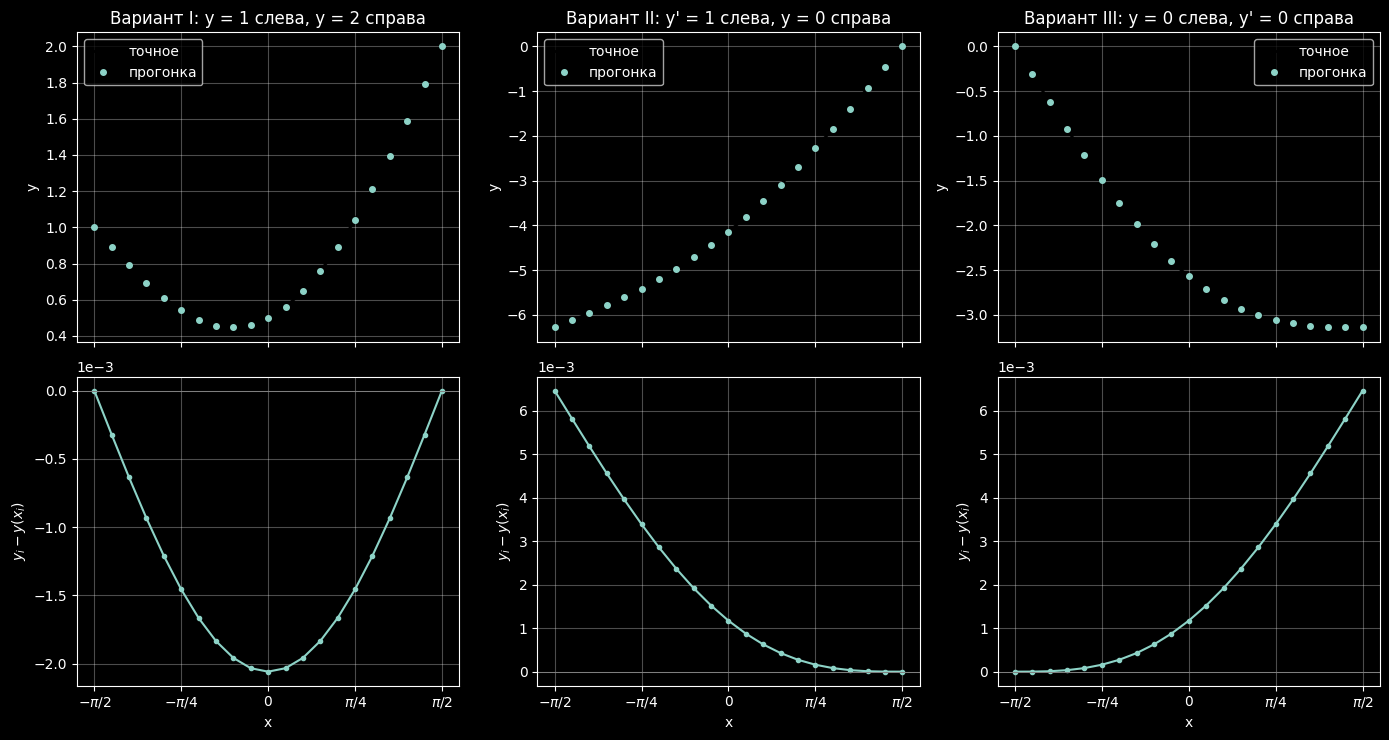

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
x_fine = np.linspace(x_left, x_right, 401)
for k, (name, v) in enumerate(variants.items()):
    x, y = results[name]
    ax = axes[0, k]
    ax.plot(x_fine, v["exact"](x_fine), "k-", linewidth=2, label="точное")
    ax.plot(x, y, "o", markersize=4, label="прогонка")
    (kl, vl), (kr, vr) = v["left"], v["right"]
    bc = lambda kind, val: ("y" if kind == "y" else "y'") + f" = {val:g}"
    ax.set(title=f"Вариант {name}: {bc(kl, vl)} слева, {bc(kr, vr)} справа",
           ylabel="y")
    ax.legend()
    ax = axes[1, k]
    ax.plot(x, y - v["exact"](x), "o-", markersize=3)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.set(xlabel="x", ylabel=r"$y_i-y(x_i)$")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
for ax in axes.flat:
    ax.set_xticks([-np.pi/2, -np.pi/4, 0, np.pi/4, np.pi/2],
                  [r"$-\pi/2$", r"$-\pi/4$", r"$0$", r"$\pi/4$", r"$\pi/2$"])
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

В варианте I ошибка обращается в нуль на обоих концах, где значения заданы
точно. В вариантах II и III на конце с условием на производную значение
функции находится из схемы и тоже содержит ошибку.

Опорные элементы нигде не обращаются в нуль. Наименьший из них
в варианте III равен $\widetilde b_N=1-\frac{N-1}{N}=\frac1N$:
при условии на функцию слева $\widetilde b_i=-\frac{i+1}{i}$, как в лекции
(с точностью до знака), и последняя строка $-y_{N-1}+y_N$ почти
сокращается с предыдущей. Для прогонки это не опасно.

## Проверка порядка точности.

Для каждого варианта вычислим
$E_N=\max_i|y_i-y(x_i)|$ на сгущающихся сетках и наблюдаемый порядок
$p=\log_2(E_N/E_{2N})$. Ожидаем $p\to2$.

In [7]:
N_values = np.array([10, 20, 40, 80, 160, 320, 640])
convergence = {}
for name, v in variants.items():
    errors = []
    print("\nВариант", name)
    print(f"{'N':>6} {'h':>10} {'E_N':>14} {'Порядок':>10}")
    for n in N_values:
        x, a, b, c, d = build_system(n, v["left"], v["right"])
        error = np.max(np.abs(solve_tridiagonal(a, b, c, d) - v["exact"](x)))
        order = np.log2(errors[-1] / error) if errors else np.nan
        order_text = f"{order:.4f}" if np.isfinite(order) else "—"
        print(f"{n:6d} {np.pi/n:10.5f} {error:14.5e} {order_text:>10}")
        errors.append(error)
    convergence[name] = np.array(errors)
    assert abs(order - 2) < 0.01


Вариант I
     N          h            E_N    Порядок
    10    0.31416    8.26542e-03          —
    20    0.15708    2.05871e-03     2.0053
    40    0.07854    5.14200e-04     2.0013
    80    0.03927    1.28520e-04     2.0003
   160    0.01963    3.21282e-05     2.0001
   320    0.00982    8.03194e-06     2.0000
   640    0.00491    2.00798e-06     2.0000

Вариант II
     N          h            E_N    Порядок
    10    0.31416    2.58812e-02          —
    20    0.15708    6.46230e-03     2.0018
    40    0.07854    1.61508e-03     2.0004
    80    0.03927    4.03738e-04     2.0001
   160    0.01963    1.00933e-04     2.0000
   320    0.00982    2.52330e-05     2.0000
   640    0.00491    6.30825e-06     2.0000

Вариант III
     N          h            E_N    Порядок
    10    0.31416    2.58812e-02          —
    20    0.15708    6.46230e-03     2.0018
    40    0.07854    1.61508e-03     2.0004
    80    0.03927    4.03738e-04     2.0001
   160    0.01963    1.00933e-04     2.0

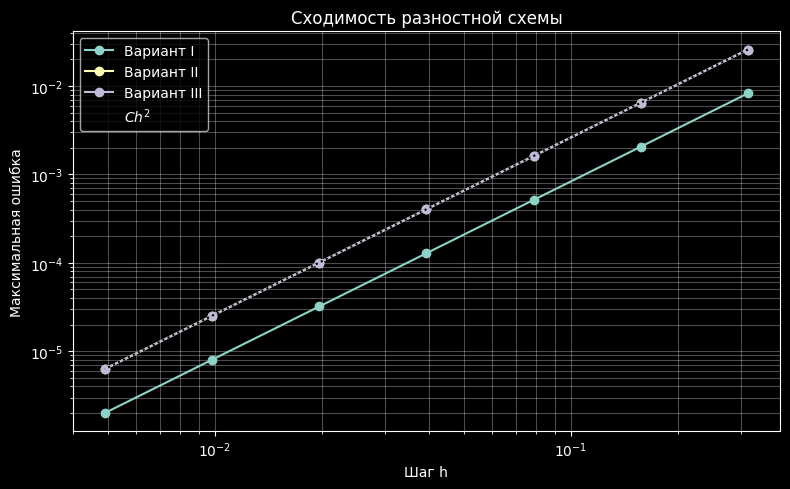

In [8]:
h_values = np.pi / N_values
fig, ax = plt.subplots(figsize=(8, 5))
for name in variants:
    ax.loglog(h_values, convergence[name], "o-", label="Вариант " + name)
ax.loglog(h_values, convergence["II"][-1] * (h_values / h_values[-1])**2, "k:",
          label=r"$C h^2$")
ax.set(xlabel="Шаг h", ylabel="Максимальная ошибка",
       title="Сходимость разностной схемы")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Порядок аппроксимации условия на производную.

Покажем, зачем нужна поправка $\frac{h^2}{2}y''_0$. Сдвинем отрезок так,
чтобы на границе $\cos x\ne0$: решим ту же задачу на $[0,\pi/2]$
с условиями $y'(0)=0$, $y(\pi/2)=0$. Точное решение
$y=-\cos x$, $y''(0)=1\ne0$. Сравним граничную строку
без поправки, $(y_1-y_0)/h=\alpha$, и с поправкой.

In [9]:
def solve_shifted(N, correction):
    x = np.linspace(0, np.pi/2, N + 1)
    h = np.pi / 2 / N
    a, b, c, d = np.ones(N + 1), -2*np.ones(N + 1), np.ones(N + 1), h**2*f(x)
    a[0], c[N] = 0.0, 0.0
    b[0], c[0], d[0] = -1.0, 1.0, h*0.0 + (h**2/2*f(x[0]) if correction else 0.0)
    a[N], b[N], d[N] = 0.0, 1.0, 0.0
    return x, solve_tridiagonal(a, b, c, d)


print(f"{'N':>6} {'без поправки':>14} {'p':>7} {'с поправкой':>14} {'p':>7}")
previous = None
for n in [10, 20, 40, 80, 160, 320]:
    errors = [np.max(np.abs(y + np.cos(x)))
              for x, y in (solve_shifted(n, False), solve_shifted(n, True))]
    if previous is None:
        print(f"{n:6d} {errors[0]:14.5e} {'—':>7} {errors[1]:14.5e} {'—':>7}")
    else:
        p = [np.log2(e0 / e1) for e0, e1 in zip(previous, errors)]
        print(f"{n:6d} {errors[0]:14.5e} {p[0]:7.3f} {errors[1]:14.5e} {p[1]:7.3f}")
    previous = errors

     N   без поправки       p    с поправкой       p
    10    1.21311e-01       —    2.05871e-03       —
    20    6.11708e-02   0.988    5.14200e-04   2.001
    40    3.07140e-02   0.994    1.28520e-04   2.000
    80    1.53891e-02   0.997    3.21282e-05   2.000
   160    7.70260e-03   0.998    8.03194e-06   2.000
   320    3.85331e-03   0.999    2.00798e-06   2.000


Без поправки граничная строка аппроксимирует условие лишь с ошибкой $O(h)$,
и порядок всей схемы падает до первого. С поправкой сохраняется второй
порядок. На исходном отрезке $[-\pi/2,\pi/2]$ обе формулы совпадают,
поскольку $\cos(\pm\pi/2)=0$.

## Вариант IV: условия на производную на обоих концах.

Возьмём $y'(-\pi/2)=0$, $y'(\pi/2)=2$, так что непрерывное условие
разрешимости выполнено. Найдём опорные элементы прогонки.
Слева $\widetilde b_0=-1$, $c_0=1$, поэтому во внутренних строках

$$
    \widetilde b_i=-2-\frac{1\cdot1}{-1}=-1, \qquad i=1,\ldots,N-1,
$$

а в последней строке $a_N=-1$, $b_N=1$:

$$
    \widetilde b_N=1-\frac{(-1)\cdot1}{-1}=0.
$$

Матрица вырождена: в каждой строке сумма коэффициентов равна нулю,
то есть $y_i=\mathrm{const}$ лежит в её ядре — как и у непрерывной задачи.

In [10]:
N = 20
x, a, b, c, d = build_system(N, ("dy", 0.0), ("dy", 2.0))
print("Опорные элементы b̃:", find_pivots(a, b, c)[[0, 1, 2, N-1, N]])
try:
    solve_tridiagonal(a, b, c, d)
except ZeroDivisionError as error:
    print("Прогонка остановлена:", error)

Опорные элементы b̃: [-1. -1. -1. -1.  0.]
Прогонка остановлена: нулевой опорный элемент b̃[20] = 0.000e+00


Складывая все строки системы, получим дискретное условие разрешимости.
Внутренние строки, делённые на $h$, телескопически сокращаются,
а граничные строки дают

$$
    \beta-\alpha=h\left[\frac{\cos x_0}{2}+\sum_{i=1}^{N-1}\cos x_i
    +\frac{\cos x_N}{2}\right],
$$

то есть справа стоит **формула трапеций** для $\int\cos x\,dx=2$.
Она равна $2$ лишь приближённо, поэтому при $\beta-\alpha=2$ разностная
задача не имеет решения, хотя непрерывная имеет бесконечно много решений.

In [11]:
print(f"{'N':>6} {'β - α':>8} {'трапеции T_N':>16} {'2 - T_N':>12}")
for n in [10, 20, 40, 80]:
    x = np.linspace(x_left, x_right, n + 1)
    h = np.pi / n
    trapezoid = h * (f(x[0])/2 + np.sum(f(x[1:-1])) + f(x[-1])/2)
    print(f"{n:6d} {2.0:8.1f} {trapezoid:16.12f} {2 - trapezoid:12.4e}")

     N    β - α     трапеции T_N      2 - T_N
    10      2.0   1.983523537509   1.6476e-02
    20      2.0   1.995885972709   4.1140e-03
    40      2.0   1.998971810497   1.0282e-03
    80      2.0   1.999742972446   2.5703e-04


Чтобы выделить единственное решение, нужно дополнительное условие
на саму функцию: например, задать значение на одном из концов.
Тогда одно из условий на производную становится лишним, и мы
возвращаемся к вариантам II или III. Значит, хотя бы одно граничное
условие должно задавать значение функции.

## Ответ.

Разностная задача

$$
    \boxed{y_{i-1}-2y_i+y_{i+1}=h^2\cos x_i, \qquad
    x_i=-\frac\pi2+ih, \quad h=\frac\pi N}
$$

с граничными строками

$$
    y_0=A \qquad\text{или}\qquad -y_0+y_1=h\alpha+\frac{h^2}2\cos x_0
$$

(и аналогично справа) решается прогонкой за $O(N)$ операций.
Получены решения

$$
\boxed{
\begin{aligned}
    &\text{I:}\ \ y(-\tfrac\pi2)=1,\ y(\tfrac\pi2)=2: &&y=-\cos x+\tfrac x\pi+\tfrac32,\\
    &\text{II:}\ \ y'(-\tfrac\pi2)=1,\ y(\tfrac\pi2)=0: &&y=-\cos x+2x-\pi,\\
    &\text{III:}\ \ y(-\tfrac\pi2)=0,\ y'(\tfrac\pi2)=0: &&y=-\cos x-x-\tfrac\pi2.
\end{aligned}}
$$

Во всех трёх вариантах наблюдаемый порядок точности равен $2$.
Для условия на производную нужна граничная формула второго порядка;
без поправки $\frac{h^2}2y''_0$ порядок падает до первого.
При условиях на производную на обоих концах (вариант IV) задача
некорректна: решение определено с точностью до константы,
матрица вырождена, и прогонка останавливается на $\widetilde b_N=0$.